# Novedad y costo del umbral

**Nivel 2 — Análisis aplicado**  
**Prerrequisitos:** nivel 1 y arreglos/logaritmos; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

Detección de novedad usa puntaje y umbral fijado por política de calibración. Sensibilidad TP/(TP+FN), especificidad TN/(TN+FP); alta especificidad puede coexistir con cero detecciones OOD. Evaluación guardada: 160 casos de calibración, 80 OOD, TP=0, FN=80, FP=1, TN=159. Recalcule y grafique los cuatro conteos y ambas tasas, no solo exactitud. No reajuste con etiquetas OOD. Resultado negativo para ese conjunto y umbral, no prueba de que ninguna anomalía sea detectable. La interpretación depende del generador/partición; uso real exige dominios externos independientes y costos operativos calibrados.

Errores pareados controlan dificultad, pero 160 realizaciones muestrean el generador, no geología natural independiente. Errores CNN están normalizados y requieren escala objetivo² para MSE físico. Separe por realización para evitar fuga; otro sitio/sensor es una prueba de transferencia más fuerte. No elija umbral OOD usando etiquetas OOD.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Recompute novelty detector rates from the persisted confusion counts.
import json
from pathlib import Path
d=json.loads((root/"data/derived/v2/models/training.json").read_text(encoding="utf-8")); e=d["novelty_evaluation"]; tp,fn,fp,tn=[e[k] for k in ("true_positive","false_negative","false_positive","true_negative")]; sens=tp/(tp+fn); spec=tn/(tn+fp)
print("calibration/OOD",e["calibration_count"],e["ood_count"],"threshold",d["novelty_threshold"],"TP FN FP TN",tp,fn,fp,tn,"sensitivity",sens,"specificity",spec,"AUC",e.get("roc_auc"))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
calibration/OOD 160 80 threshold 0.07312346994876862 TP FN FP TN 0 80 1 159 sensitivity 0.0 specificity 0.99375 AUC 0.43109375


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

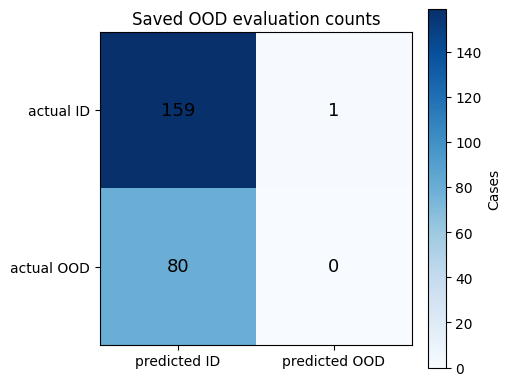

Sensitivity 0.0 specificity 0.99375 AUC 0.43109375


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Show all confusion counts so zero sensitivity cannot be hidden by high specificity.
import matplotlib.pyplot as plt
mat=np.array([[tn,fp],[fn,tp]]); fig,ax=plt.subplots(figsize=(5,4),constrained_layout=True); im=ax.imshow(mat,cmap="Blues"); ax.set(xticks=[0,1],xticklabels=["predicted ID","predicted OOD"],yticks=[0,1],yticklabels=["actual ID","actual OOD"],title="Saved OOD evaluation counts")
for (i,j),v in np.ndenumerate(mat): ax.text(j,i,str(v),ha="center",va="center",fontsize=13)
fig.colorbar(im,ax=ax,label="Cases"); plt.show(); print("Sensitivity",sens,"specificity",spec,"AUC",e.get("roc_auc"))

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)